In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import string
import re
import nltk
import nltk.corpus
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
# Text Polarity
from textblob import TextBlob

# Text Vectorizer
from sklearn.feature_extraction.text import CountVectorizer

# Word Cloud
from wordcloud import WordCloud

In [ ]:
 #Label Encoding
from sklearn.preprocessing import LabelEncoder

# TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Resampling
from imblearn.over_sampling import SMOTE
from collections import Counter

# Splitting Dataset
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

# Model Metrics
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [ ]:
dataset = pd.read_csv("Instruments_Reviews.csv")

# New Section

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset.shape

(10261, 9)

**Data processing**

In [ ]:
dataset.isnull().sum()

,0
reviewerID,0
asin,0
reviewerName,27
helpful,0
reviewText,7
overall,0
summary,0
unixReviewTime,0
reviewTime,0


In [ ]:
dataset.reviewText.fillna(value = "", inplace = True)

/tmp/ipykernel_3030/2670805535.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset.reviewText.fillna(value = "", inplace = True)


**Filling Missing Values**

In [ ]:
dataset.reviewText.fillna(value = "", inplace = True)

**Concatenate reviewText and summary Columns**



In [ ]:
dataset["reviews"] = dataset["reviewText"] + " " + dataset["summary"]
dataset.drop(columns = ["reviewText", "summary"], axis = 1, inplace = True)


**Statistic Description of The Dataset**

In [ ]:
dataset.describe(include = "all")

,reviewerID,asin,reviewerName,helpful,overall,unixReviewTime,reviewTime,reviews
count,10261,10261,10234,10261,10261.000000,1.026100e+04,10261,10261
unique,1429,900,1397,269,NaN,NaN,1570,10261
top,ADH0O8UVJOT10,B003VWJ2K8,Amazon Customer,"[0, 0]",NaN,NaN,"01 22, 2013","These strings are really quite good, but I wou..."
freq,42,163,66,6796,NaN,NaN,40,1
mean,NaN,NaN,NaN,NaN,4.488744,1.360606e+09,NaN,NaN
std,NaN,NaN,NaN,NaN,0.894642,3.779735e+07,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.095466e+09,NaN,NaN
25%,NaN,NaN,NaN,NaN,4.000000,1.343434e+09,NaN,NaN
50%,NaN,NaN,NaN,NaN,5.000000,1.368490e+09,NaN,NaN
75%,NaN,NaN,NaN,NaN,5.000000,1.388966e+09,NaN,NaN


**Percentages of Ratings Given from The Customers**

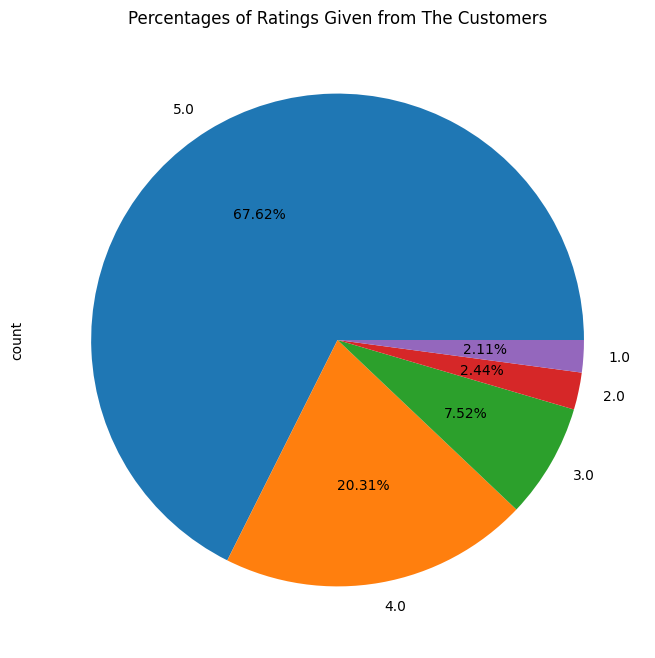

In [ ]:
dataset.overall.value_counts().plot(kind = "pie", legend = False, autopct = "%1.2f%%", fontsize = 10, figsize=(8,8))
plt.title("Percentages of Ratings Given from The Customers", loc = "center")
plt.show()


Labelling Products Based On Ratings Given

In [ ]:
def Labelling(Rows):
  if(Rows["overall"] > 3.0):
    Label = "Positive"
  elif(Rows["overall"] < 3.0):
    Label = "Negative"
  else:
    Label = "Neutral"
  return Label

In [ ]:
dataset["sentiment"] = dataset.apply(Labelling, axis = 1)

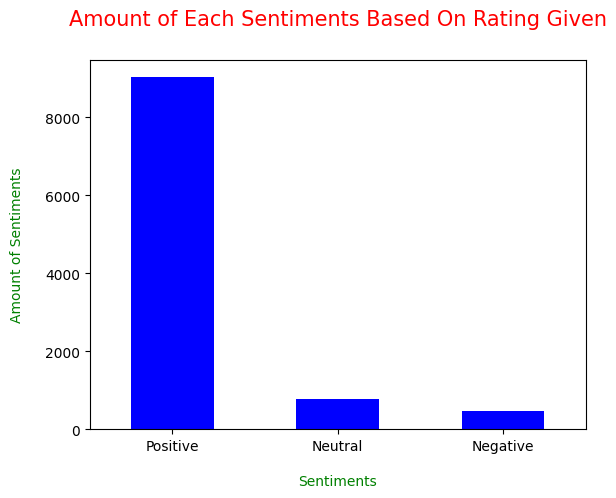

In [ ]:
dataset["sentiment"].value_counts().plot(kind = "bar", color = "blue")
plt.title("Amount of Each Sentiments Based On Rating Given", loc = "center", fontsize = 15, color = "red", pad = 25)
plt.xlabel("Sentiments", color = "green", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Amount of Sentiments", color = "green", fontsize = 10, labelpad = 15)
plt.show()

**Text Preprocessing**


Text Cleaning



In [ ]:
def Text_Cleaning(Text):
  # Lowercase the texts
  Text = Text.lower()

  # Cleaning punctuations in the text
  punc = str.maketrans(string.punctuation, ' '*len(string.punctuation))
  Text = Text.translate(punc)

  # Removing numbers in the text
  Text = re.sub(r'\d+', '', Text)

  # Remove possible links
  Text = re.sub('https?://\S+|www\.\S+', '', Text)

  # Deleting newlines
  Text = re.sub('\n', '', Text)

  return Text


<>:13: SyntaxWarning: invalid escape sequence '\S'
<>:13: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_3030/3751631284.py:13: SyntaxWarning: invalid escape sequence '\S'
  Text = re.sub('https?://\S+|www\.\S+', '', Text)


**Text Processing**

In [ ]:
Stopwords = set(nltk.corpus.stopwords.words("english")) - set(["not"])

def Text_Processing(Text):
  Processed_Text = list()
  Lemmatizer = WordNetLemmatizer()

  # Tokens of Words
  Tokens = nltk.word_tokenize(Text)

  # Removing Stopwords and Lemmatizing Words
  # To reduce noises in our dataset, also to keep it simple and still
  # powerful, we will only omit the word `not` from the list of stopwords

  for word in Tokens:
    if word not in Stopwords:
      Processed_Text.append(Lemmatizer.lemmatize(word))

  return(" ".join(Processed_Text))


**Applying The Functions**

In [ ]:
import nltk
nltk.download('punkt_tab')

dataset["reviews"] = dataset["reviews"].apply(lambda Text: Text_Cleaning(Text))
dataset["reviews"] = dataset["reviews"].apply(lambda Text: Text_Processing(Text))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


**Exploratory Data Analysis**

Overview of The Dataset

In [ ]:
dataset.head(n = 10)

,reviewerID,asin,reviewerName,helpful,overall,unixReviewTime,reviewTime,reviews,sentiment
0,A2IBPI20UZIR0U,1384719342,"cassandra tu ""Yeah, well, that's just like, u...","[0, 0]",5.0,1393545600,"02 28, 2014",not much write exactly supposed filter pop sou...,Positive
1,A14VAT5EAX3D9S,1384719342,Jake,"[13, 14]",5.0,1363392000,"03 16, 2013",product exactly quite affordable not realized ...,Positive
2,A195EZSQDW3E21,1384719342,"Rick Bennette ""Rick Bennette""","[1, 1]",5.0,1377648000,"08 28, 2013",primary job device block breath would otherwis...,Positive
3,A2C00NNG1ZQQG2,1384719342,"RustyBill ""Sunday Rocker""","[0, 0]",5.0,1392336000,"02 14, 2014",nice windscreen protects mxl mic prevents pop ...,Positive
4,A94QU4C90B1AX,1384719342,SEAN MASLANKA,"[0, 0]",5.0,1392940800,"02 21, 2014",pop filter great look performs like studio fil...,Positive
5,A2A039TZMZHH9Y,B00004Y2UT,"Bill Lewey ""blewey""","[0, 0]",5.0,1356048000,"12 21, 2012",good bought another one love heavy cord gold c...,Positive
6,A1UPZM995ZAH90,B00004Y2UT,Brian,"[0, 0]",5.0,1390089600,"01 19, 2014",used monster cable year good reason lifetime w...,Positive
7,AJNFQI3YR6XJ5,B00004Y2UT,"Fender Guy ""Rick""","[0, 0]",3.0,1353024000,"11 16, 2012",use cable run output pedal chain input fender ...,Neutral
8,A3M1PLEYNDEYO8,B00004Y2UT,"G. Thomas ""Tom""","[0, 0]",5.0,1215302400,"07 6, 2008",perfect epiphone sheraton ii monster cable wel...,Positive
9,AMNTZU1YQN1TH,B00004Y2UT,Kurt Robair,"[0, 0]",5.0,1389139200,"01 8, 2014",monster make best cable lifetime warranty does...,Positive


About Other Features

In [ ]:
dataset.describe(include = "all")

,reviewerID,asin,reviewerName,helpful,overall,unixReviewTime,reviewTime,reviews,sentiment
count,10261,10261,10234,10261,10261.000000,1.026100e+04,10261,10261,10261
unique,1429,900,1397,269,NaN,NaN,1570,10254,3
top,ADH0O8UVJOT10,B003VWJ2K8,Amazon Customer,"[0, 0]",NaN,NaN,"01 22, 2013",good string five star,Positive
freq,42,163,66,6796,NaN,NaN,40,3,9022
mean,NaN,NaN,NaN,NaN,4.488744,1.360606e+09,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,0.894642,3.779735e+07,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.095466e+09,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,4.000000,1.343434e+09,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,5.000000,1.368490e+09,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,5.000000,1.388966e+09,NaN,NaN,NaN


Polarity, Review Length, and Word Counts

In [ ]:
dataset["polarity"] = dataset["reviews"].map(lambda Text: TextBlob(Text).sentiment.polarity)


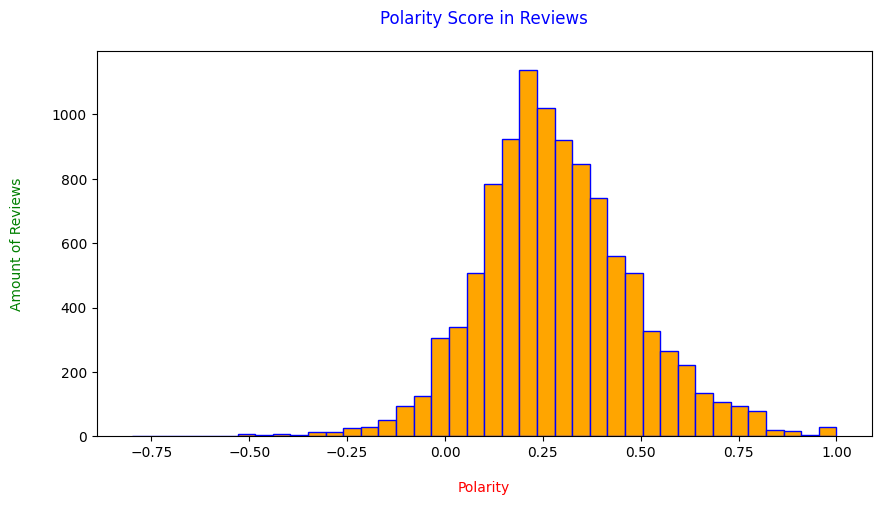

In [ ]:
dataset["polarity"].plot(kind = "hist", bins = 40, edgecolor = "blue", linewidth = 1, color = "orange", figsize = (10,5))
plt.title("Polarity Score in Reviews", color = "blue", pad = 20)
plt.xlabel("Polarity", labelpad = 15, color = "red")
plt.ylabel("Amount of Reviews", labelpad = 20, color = "green")

plt.show()

In [ ]:
dataset["length"] = dataset["reviews"].astype(str).apply(len)

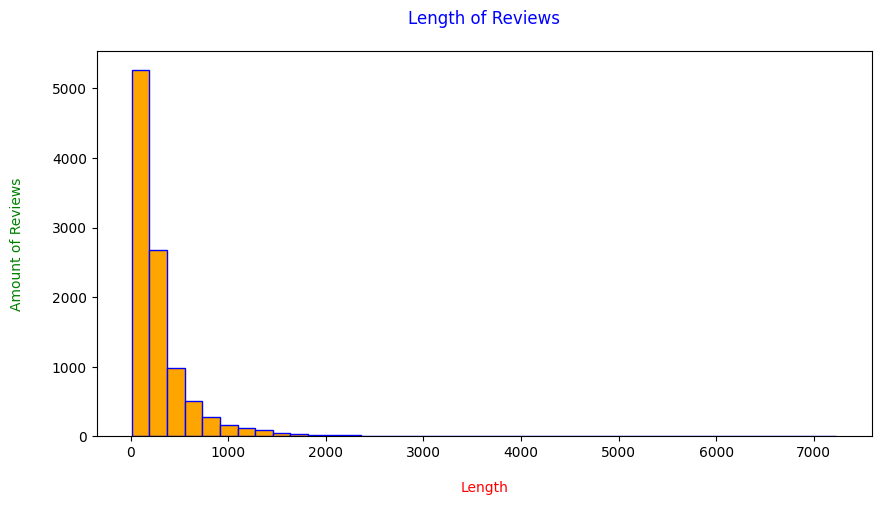

In [ ]:
dataset["length"].plot(kind = "hist", bins = 40, edgecolor = "blue", linewidth = 1, color = "orange", figsize = (10,5))
plt.title("Length of Reviews", color = "blue", pad = 20)
plt.xlabel("Length", labelpad = 15, color = "red")
plt.ylabel("Amount of Reviews", labelpad = 20, color = "green")

plt.show()

Word counts

In [ ]:
dataset["word_counts"] = dataset["reviews"].apply(lambda x: len(str(x).split()))


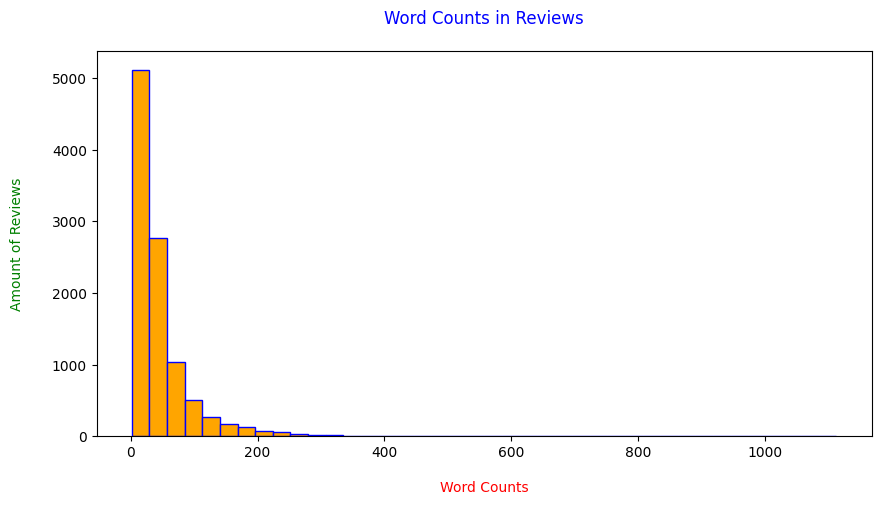

In [ ]:
dataset["word_counts"].plot(kind = "hist", bins = 40, edgecolor = "blue", linewidth = 1, color = "orange", figsize = (10,5))
plt.title("Word Counts in Reviews", color = "blue", pad = 20)
plt.xlabel("Word Counts", labelpad = 15, color = "red")
plt.ylabel("Amount of Reviews", labelpad = 20, color = "green")

plt.show()

**N-Gram Analysis**

**N-Gram Function**

In [ ]:
def Gram_Analysis(Corpus, Gram, N):
  # Vectorizer (converting Stopwords set to list to prevent validation errors)
  Vectorizer = CountVectorizer(stop_words = list(Stopwords), ngram_range=(Gram,Gram))

  # N-Grams Matrix
  ngrams = Vectorizer.fit_transform(Corpus)

  # N-Grams Frequency
  Count = ngrams.sum(axis=0)

  # List of Words
  words = [(word, Count[0, idx]) for word, idx in Vectorizer.vocabulary_.items()]

  # Sort Descending With Key = Count
  words = sorted(words, key = lambda x:x[1], reverse = True)

  return words[:N]

**Filter The DataFrame Based On Sentiments**

In [ ]:
Positive = dataset[dataset["sentiment"] == "Positive"].dropna()
Neutral = dataset[dataset["sentiment"] == "Neutral"].dropna()
Negative = dataset[dataset["sentiment"] == "Negative"].dropna()


**Unigram of Reviews Based on Sentiments**


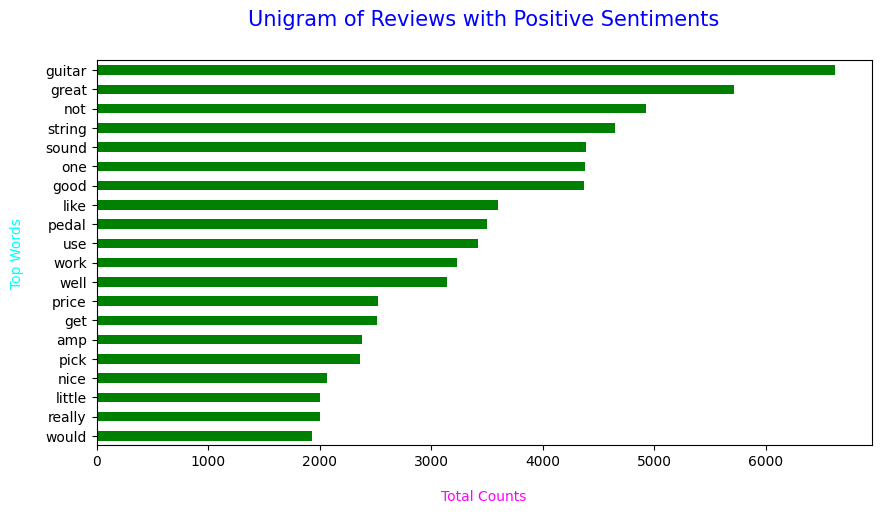

In [ ]:
# Finding Unigram
# Convert Stopwords set to list to satisfy CountVectorizer requirements
words = Gram_Analysis(Positive["reviews"], 1, 20)
Unigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Unigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "green", figsize = (10, 5))
plt.title("Unigram of Reviews with Positive Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()

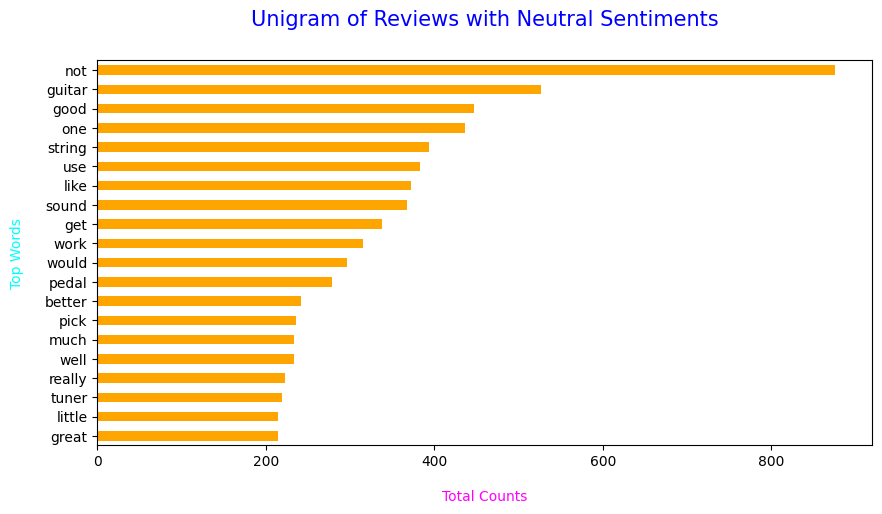

In [ ]:
words = Gram_Analysis(Neutral["reviews"], 1, 20)
Unigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Unigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "orange", figsize = (10, 5))
plt.title("Unigram of Reviews with Neutral Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()

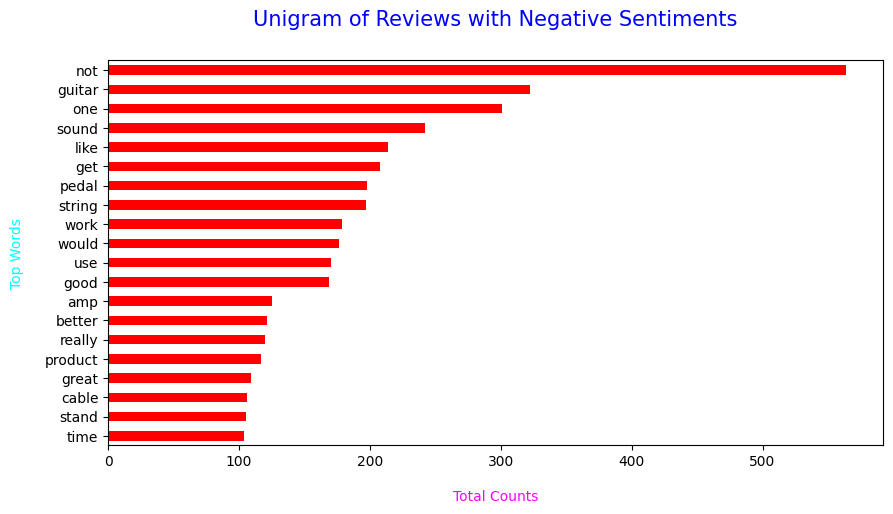

In [ ]:
# Finding Unigram
words = Gram_Analysis(Negative["reviews"], 1, 20)
Unigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Unigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "red", figsize = (10, 5))
plt.title("Unigram of Reviews with Negative Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()


**Bigram of Reviews Based On Sentiments**

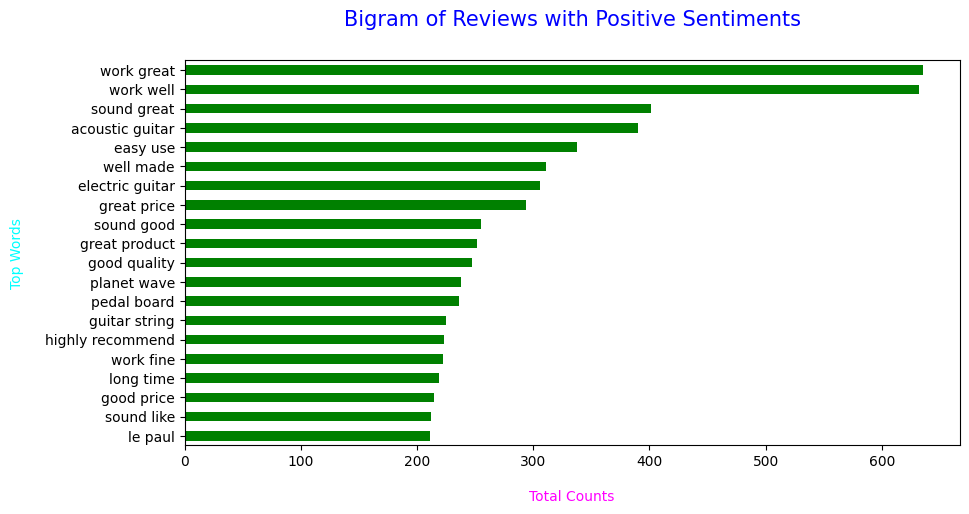

In [ ]:
# Finding Bigram
words = Gram_Analysis(Positive["reviews"], 2, 20)
Bigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Bigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "green", figsize = (10, 5))
plt.title("Bigram of Reviews with Positive Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()

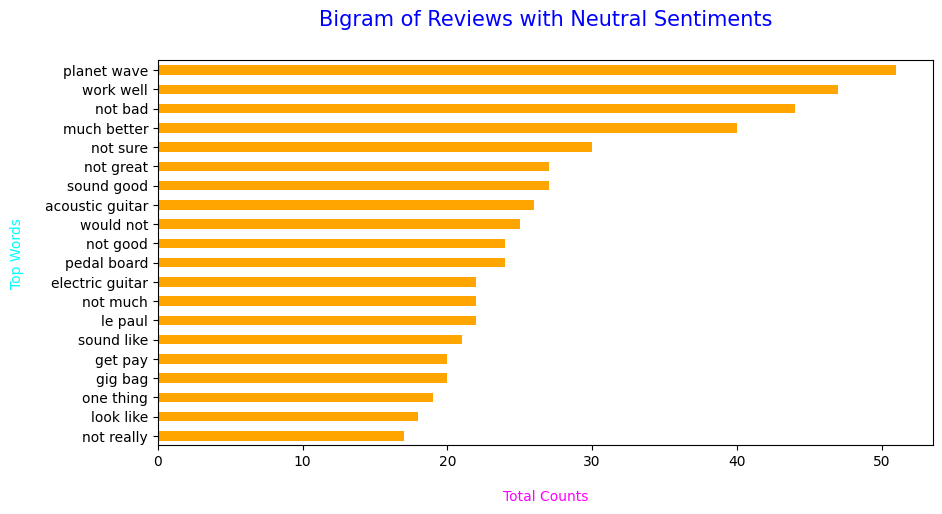

In [ ]:

# Finding Bigram
words = Gram_Analysis(Neutral["reviews"], 2, 20)
Bigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Bigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "orange", figsize = (10, 5))
plt.title("Bigram of Reviews with Neutral Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()


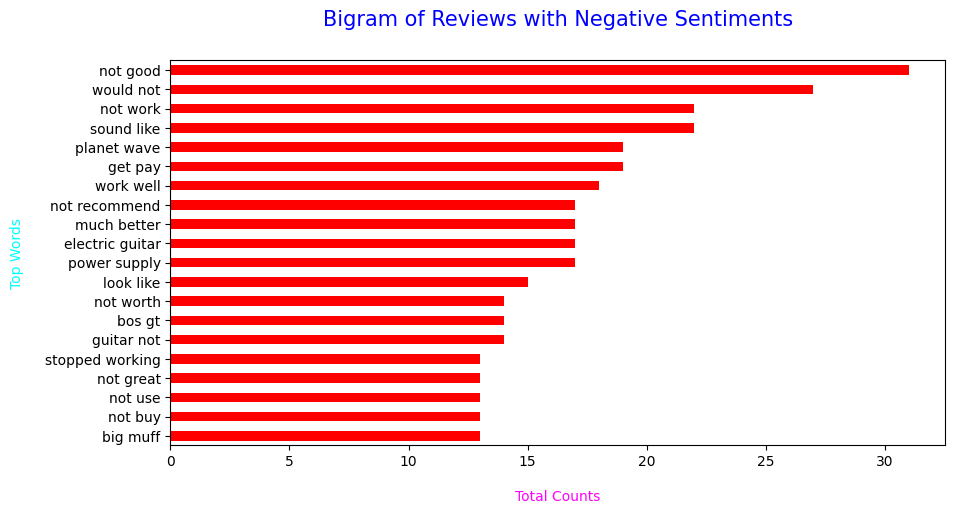

In [ ]:
# Finding Bigram
words = Gram_Analysis(Negative["reviews"], 2, 20)
Bigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Bigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "red", figsize = (10, 5))
plt.title("Bigram of Reviews with Negative Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()

**Trigram of Reviews Based On Sentiments**



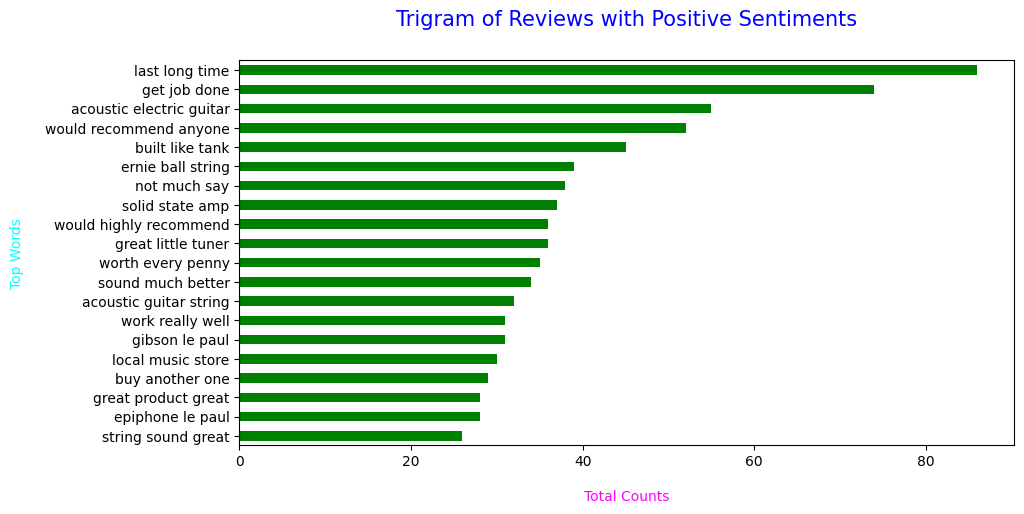

In [ ]:
# Finding Trigram
words = Gram_Analysis(Positive["reviews"], 3, 20)
Trigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Trigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "green", figsize = (10, 5))
plt.title("Trigram of Reviews with Positive Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()

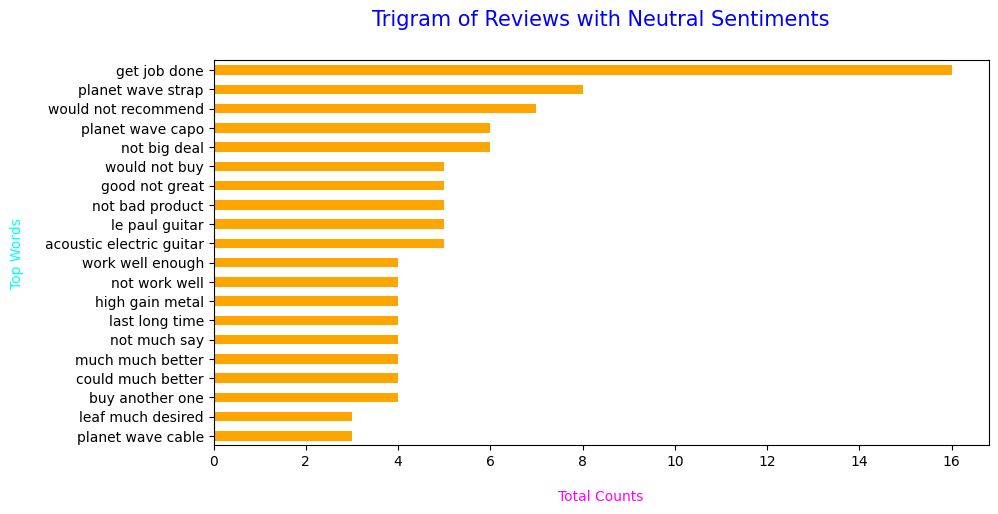

In [ ]:
words = Gram_Analysis(Neutral["reviews"], 3, 20)
Trigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Trigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "orange", figsize = (10, 5))
plt.title("Trigram of Reviews with Neutral Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()

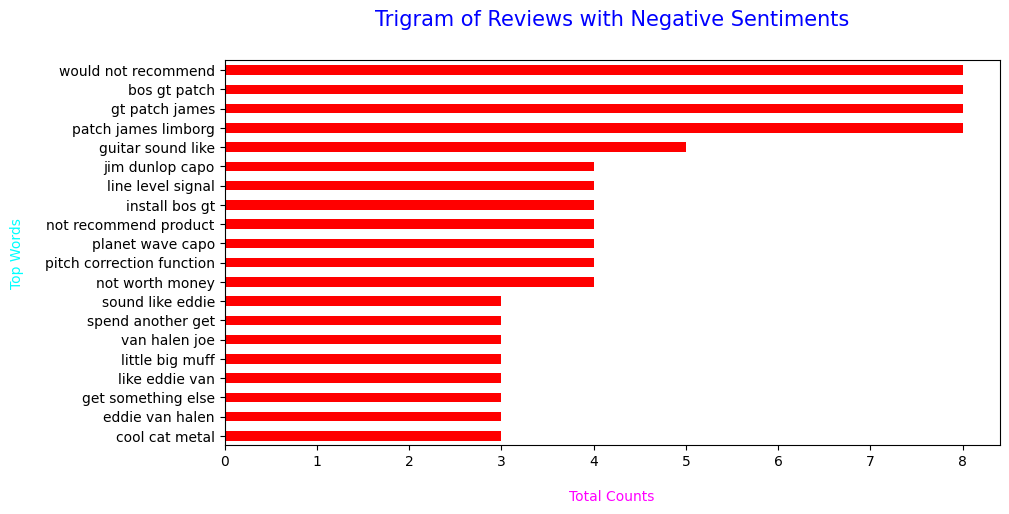

In [ ]:
# Finding Trigram
words = Gram_Analysis(Negative["reviews"], 3, 20)
Trigram = pd.DataFrame(words, columns = ["Words", "Counts"])

# Visualization
Trigram.groupby("Words").sum()["Counts"].sort_values().plot(kind = "barh", color = "red", figsize = (10, 5))
plt.title("Trigram of Reviews with Negative Sentiments", loc = "center", fontsize = 15, color = "blue", pad = 25)
plt.xlabel("Total Counts", color = "magenta", fontsize = 10, labelpad = 15)
plt.xticks(rotation = 0)
plt.ylabel("Top Words", color = "cyan", fontsize = 10, labelpad = 15)
plt.show()


Word Clouds

Word Cloud of Reviews with Positive Sentiments

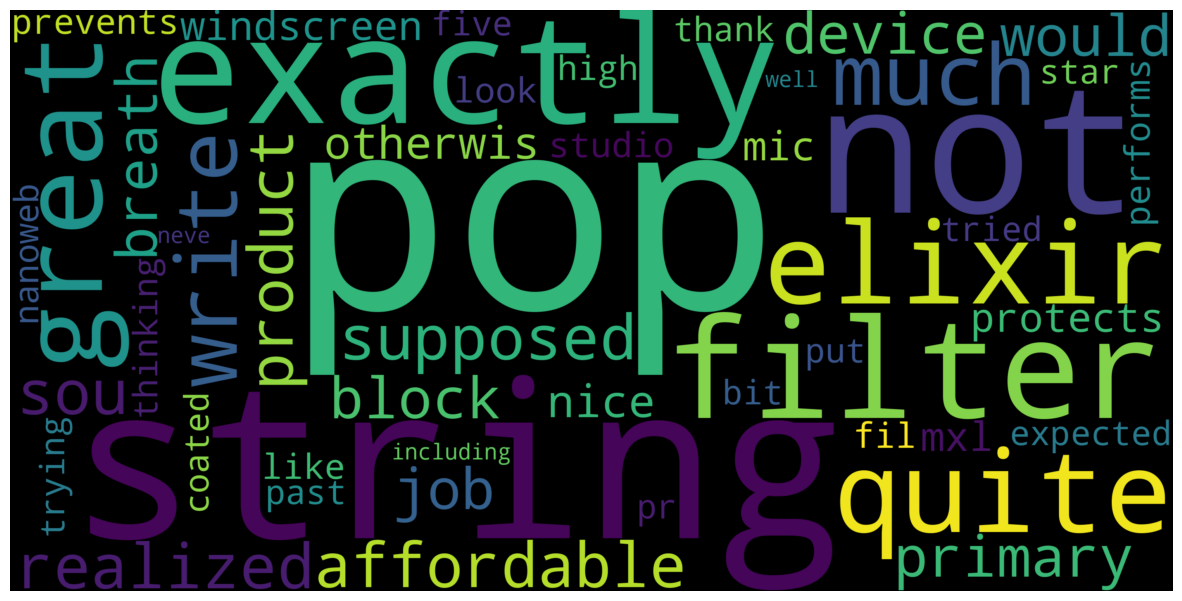

In [ ]:
wordCloud = WordCloud(max_words = 50, width = 3000, height = 1500, stopwords = Stopwords).generate(str(Positive["reviews"]))
plt.figure(figsize = (15, 15))
plt.imshow(wordCloud, interpolation = "bilinear")
plt.axis("off")
plt.show()

**Word Cloud of Reviews with Neutral Sentiments**

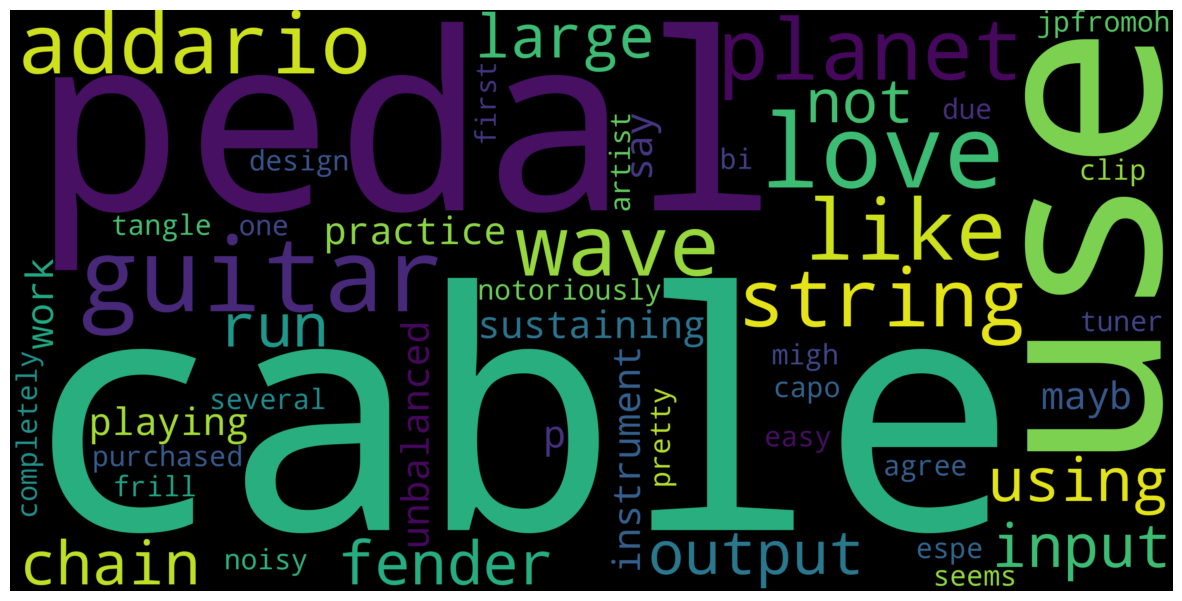

In [ ]:
wordCloud = WordCloud(max_words = 50, width = 3000, height = 1500, stopwords = Stopwords).generate(str(Neutral["reviews"]))
plt.figure(figsize = (15, 15))
plt.imshow(wordCloud, interpolation = "bilinear")
plt.axis("off")
plt.show()


**Word Cloud of Reviews with Negative Sentiments**

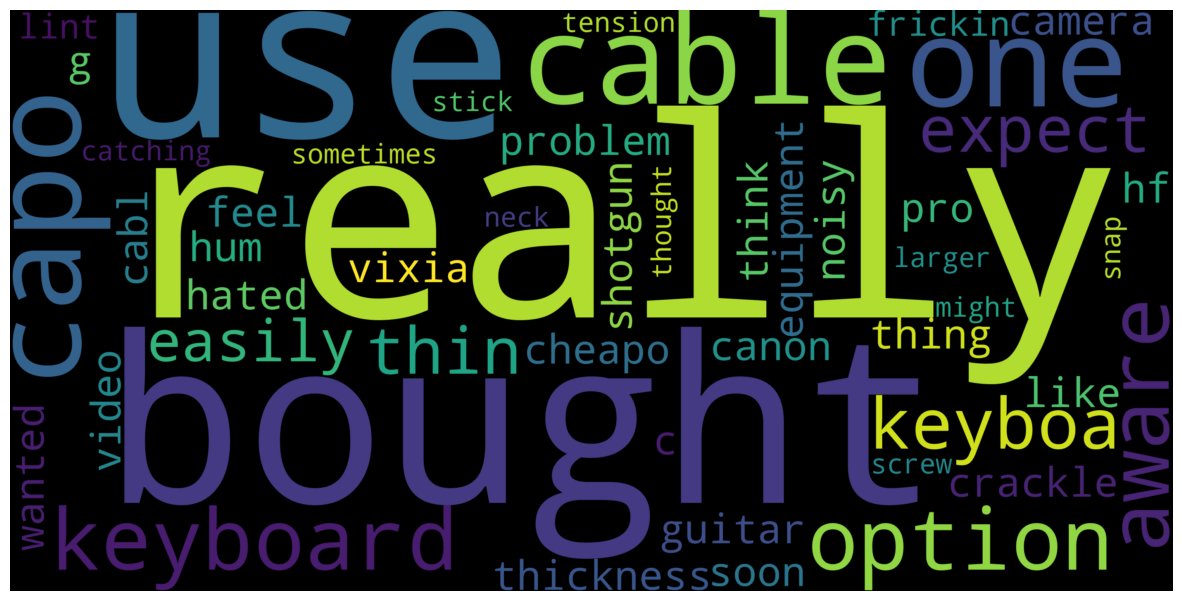

In [ ]:
wordCloud = WordCloud(max_words = 50, width = 3000, height = 1500, stopwords = Stopwords).generate(str(Negative["reviews"]))
plt.figure(figsize = (15, 15))
plt.imshow(wordCloud, interpolation = "bilinear")
plt.axis("off")
plt.show()

**Feature Engineering**

Drop Insignificant Columns

In [ ]:
Columns = ["reviewerID", "asin", "reviewerName", "helpful", "unixReviewTime", "reviewTime", "polarity", "length", "word_counts", "overall"]
dataset.drop(columns = Columns, axis = 1, inplace = True)


**Current State of The Dataset**

In [ ]:
dataset.head()


,reviews,sentiment
0,not much write exactly supposed filter pop sou...,Positive
1,product exactly quite affordable not realized ...,Positive
2,primary job device block breath would otherwis...,Positive
3,nice windscreen protects mxl mic prevents pop ...,Positive
4,pop filter great look performs like studio fil...,Positive


**Encoding Our Target Variable**

In [ ]:
Encoder = LabelEncoder()
dataset["sentiment"] = Encoder.fit_transform(dataset["sentiment"])

In [ ]:
dataset["sentiment"].value_counts()



,count
sentiment,
2,9022
1,772
0,467


**TF-IDF Vectorizer**

In [ ]:
# Defining our vectorizer with total words of 5000 and with bigram model
TF_IDF = TfidfVectorizer(max_features = 5000, ngram_range = (2, 2))

# Fitting and transforming our reviews into a matrix of weighed words
# This will be our independent features
X = TF_IDF.fit_transform(dataset["reviews"])

# Check our matrix shape
X.shape

(10261, 5000)

In [ ]:
y = dataset["sentiment"]


**Resampling Our Dataset**

In [ ]:
Counter(y)

Counter({2: 9022, 1: 772, 0: 467})

In [ ]:
Balancer = SMOTE(random_state = 42)
X_final, y_final = Balancer.fit_resample(X, y)


In [ ]:
Counter(y_final)



Counter({2: 9022, 1: 9022, 0: 9022})

**Splitting Our Dataset**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size = 0.25, random_state = 42)


**Model Selection and Evaluation**
We do not really know what is the best model that fits our data well. Because of that, we will need to try every classification models available and find the best models using the Confusion Matrix and F1 Score as our main metrics, and the rest of the metrics as our support. First, we should do some cross validation techniques in order to find the best model.

**Model Building**

We are using K-Fold Cross Validation on our early dataset (before resampling) because the CV itself is not affected by the imbalanced dataset as it splits the dataset and takes into account every validations. If we use the CV on the balanced dataset that we got from resampling we should be able to get similar result.

In [ ]:
DTree = DecisionTreeClassifier()
LogReg = LogisticRegression()
SVC = SVC()
RForest = RandomForestClassifier()
Bayes = BernoulliNB()
KNN = KNeighborsClassifier()

Models = [DTree, LogReg, SVC, RForest, Bayes, KNN]
Models_Dict = {0: "Decision Tree", 1: "Logistic Regression", 2: "SVC", 3: "Random Forest", 4: "Naive Bayes", 5: "K-Neighbors"}

for i, model in enumerate(Models):
  print("{} Test Accuracy: {}".format(Models_Dict[i], cross_val_score(model, X, y, cv = 10, scoring = "accuracy").mean()))


Decision Tree Test Accuracy: 0.8203874529990453
Logistic Regression Test Accuracy: 0.8819802942387887
SVC Test Accuracy: 0.8805184008381876
Random Forest Test Accuracy: 0.8779848571987146
Naive Bayes Test Accuracy: 0.8097643356470805
K-Neighbors Test Accuracy: 0.8662914182567747


**Hyperparameter Tuning**

In [ ]:
Param = {"C": np.logspace(-4, 4, 50), "penalty": ['l1', 'l2']}
grid_search = GridSearchCV(estimator = LogisticRegression(random_state = 42), param_grid = Param, scoring = "accuracy", cv = 10, verbose = 0, n_jobs = -1)

grid_search.fit(X_train, y_train)
best_accuracy = grid_search.best_score_
best_parameters = grid_search.best_params_

print("Best Accuracy: {:.2f} %".format(best_accuracy*100))
print("Best Parameters:", best_parameters)


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
500 fits failed out of a total of 1000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
500 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py", line 1193, in fit
    solver = _check_so

Best Accuracy: 94.91 %
Best Parameters: {'C': np.float64(10000.0), 'penalty': 'l2'}


**Best Model**

In [ ]:
Classifier = LogisticRegression(random_state = 42, C = 6866.488450042998, penalty = 'l2')
Classifier.fit(X_train, y_train)

Prediction = Classifier.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Metrics**

In [ ]:
accuracy_score(y_test, Prediction)


0.9519728092212206

Confusion Matrix

In [ ]:
ConfusionMatrix = confusion_matrix(y_test, Prediction)

Visualizing Our Confusion Matrix

In [ ]:
# Plotting Function for Confusion Matrix
def plot_cm(cm, classes, title, normalized = False, cmap = plt.cm.Blues):

  plt.imshow(cm, interpolation = "nearest", cmap = cmap)
  plt.title(title, pad = 20)
  plt.colorbar()
  tick_marks = np.arange(len(classes))
  plt.xticks(tick_marks, classes)
  plt.yticks(tick_marks, classes)

  if normalized:
    cm = cm.astype('float') / cm.sum(axis = 1)[: np.newaxis]
    print("Normalized Confusion Matrix")
  else:
    print("Unnormalized Confusion Matrix")

  threshold = cm.max() / 2
  for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
      plt.text(j, i, cm[i, j], horizontalalignment = "center", color = "white" if cm[i, j] > threshold else "black")

  plt.tight_layout()
  plt.xlabel("Predicted Label", labelpad = 20)
  plt.ylabel("Real Label", labelpad = 20)


Unnormalized Confusion Matrix


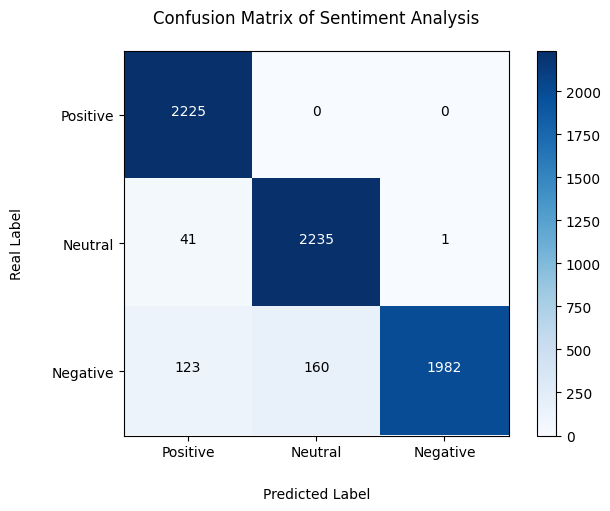

In [ ]:
plot_cm(ConfusionMatrix, classes = ["Positive", "Neutral", "Negative"], title = "Confusion Matrix of Sentiment Analysis")


Classification Scores

In [ ]:
print(classification_report(y_test, Prediction))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96      2225
           1       0.93      0.98      0.96      2277
           2       1.00      0.88      0.93      2265

    accuracy                           0.95      6767
   macro avg       0.95      0.95      0.95      6767
weighted avg       0.95      0.95      0.95      6767



**Conclusion**

**Dataset**

Our dataset contains many features about user reviews on musical instruments. But, we rarely need those features as our model variables because those features are not really important for sentiment analysis.
We might need to omit our part of removing stopwords in our preprocessing phase, because there might be some important words in determining user sentiments in our model.
From our text analysis, we know that most of the transactions made are related to guitars or other string-based instruments. We can say that guitar got a really high attention from the customers' pool and the sellers can emphasize their products on this instruments.

**Model**

We tried almost all classification models available. By using 10-Fold Cross Validation, we get that Logistic Regression Model got the best accuracy and we decided to use this model and tune it.
On our attempt on making prediction to our test set, we also received a nice accuracy and high F1 Score. This means that our model works well on sentiment analysis.
We need to consider more Cross Validation Method, such as Stratified K-Fold so that we do not really need to do resampling on our dataset. Also, we are fine without data scaling, but it is highly suggested to do it.

**Sources of Learning**

These articles and notebooks are great and really useful for sentiment analysis and NLP. Check it out!

1.Text Preprocessing in Python: Steps, Tools, and Examples

2.Sentiment Analysis — ML project from Scratch to Production (Web Application)

3.Updated Text Preprocessing techniques for Sentiment Analysis

4.Amazon Instrument: Sentimental Analysis

5.Sentiment Analysis | Amazon reviews

6.SMOTE for Imbalanced Classification with Python


Other Documentations:

1.Pandas

2.Matplotlib

3.Scikit-Learn

4.Natural Language

5.Toolkit


# Detailed Project Walkthrough & Explanation

This document provides an in-depth, step-by-step breakdown of your entire **Musical Instruments Sentiment Analysis Project**. It explains the purpose of each code section, the underlying machine learning (ML) concepts, and the libraries used.

---

## 1. Library Imports & Dependencies

### Core Utilities (`PO7seTZ_Vk0N`)
*   **`pandas (pd)`**: Used for structured data manipulation. It loads the CSV dataset, handles missing values, and organizes structured structures (DataFrames).
*   **`numpy (np)`**: Used for efficient numerical computations and multi-dimensional array operations (e.g., creating arrays of parameters for hyperparameter search).
*   **`matplotlib.pyplot (plt)`**: The primary plotting library used to build visualizations like pie charts, bar plots, histograms, and matrices.

### Natural Language Processing (NLP) Prep (`j4K-5ltuXP6M` & `Ra9QbrJlXP2z`)
*   **`string` & `re`**: Used for text cleaning. `string` provides predefined punctuation sets, and `re` implements Regular Expressions to strip URLs, numbers, and carriage returns.
*   **`nltk` (Natural Language Toolkit)**:
    *   `nltk.download(...)`: Fetches linguistic resources including English stopwords (frequently occurring words like "the", "is" that carry little semantic weight), the `punkt` tokenizer, and `wordnet` (a lexical database of English used for finding semantic relationships).
    *   `WordNetLemmatizer`: Reduces words to their base dictionary form (e.g., "running", "ran" -> "run") which normalizes vocabulary.
*   **`TextBlob`**: A simplified NLP library used here to quickly measure **Polarity** (how positive/negative a sentence is on a scale of -1 to +1).
*   **`WordCloud`**: Creates a visual representation of text data, where the size of each word indicates its frequency in the corpus.

### Feature Extraction & Machine Learning Prep (`Q6TUpMWsXPz0` & `89kfC3wiXPw5`)
*   **`LabelEncoder`**: Converts categorical target values (Positive, Neutral, Negative) into continuous integers (0, 1, 2) that algorithms can mathematically compute.
*   **`CountVectorizer` & `TfidfVectorizer`**:
    *   `CountVectorizer`: Converts a collection of text documents to a matrix of token counts (term frequencies).
    *   `TfidfVectorizer` (Term Frequency-Inverse Document Frequency): Evaluates how important a word is to a document relative to the whole dataset. Highly common words across all documents get lower weights, whereas discriminative words get higher weights.
*   **`SMOTE` (Synthetic Minority Over-sampling Technique)**: Resolves class imbalance. Since 90% of the ratings were originally "Positive", SMOTE synthetically generates data points for the minority classes (Neutral, Negative) so the model doesn't overfit to the majority class.
*   **`train_test_split`**: Splits the final vector matrices and target arrays into separate partitions (e.g., 75% for training the model and 25% for testing its generalization strength).
*   **`cross_val_score`**: Implements K-Fold cross-validation to estimate how well various algorithms perform across different folds of the data without relying on a single test set split.
*   **`GridSearchCV`**: Automates hyperparameter optimization by exhaustively searching over a specified parameter grid and finding the combination that produces the best accuracy.

---

## 2. Data Cleaning & Transformation Pipeline

1.  **Handling Missing Values**:
    *   The `reviewText` column had 7 missing values. These were filled with empty strings (`""`) to prevent string-processing operations from failing.
2.  **Concatenating Fields**:
    *   To leverage both fields for classification, the `reviewText` and `summary` columns were joined together into a single feature column `reviews` via:  
      `dataset["reviews"] = dataset["reviewText"] + " " + dataset["summary"]`
    *   Unneeded columns were dropped to reduce memory footprint.
3.  **Label Generation**:
    *   Reviews with an `overall` score > 3.0 were categorized as **Positive**, < 3.0 as **Negative**, and exactly 3.0 as **Neutral**.

---

## 3. Text Preprocessing

Before feed-forwarding text into machine learning algorithms, raw text must be converted to normalized tokens. You implemented two primary custom functions:

*   **`Text_Cleaning(Text)`**:
    1.  Converts all text to lowercase to ensure uniform word tokens (e.g., "Guitar" and "guitar" become identical).
    2.  Translates punctuation marks to space characters.
    3.  Uses regex to strip digits (`\d+`) and web links (`https?://\S+|www\.\S+`).
*   **`Text_Processing(Text)`**:
    1.  Tokenizes sentences into individual word elements.
    2.  Excludes English stopwords, *except* for the word **"not"** (since "not" heavily alters sentiment polarity, preserving it is a smart choice for sentiment classification).
    3.  Applies lemmatization to minimize vocabulary dimensionality.

---

## 4. Feature Engineering & Vectorization

*   **N-Gram Analysis**: Evaluated Unigrams (single words), Bigrams (two-word combinations), and Trigrams (three-word combinations) to see word patterns across different sentiments.
*   **TF-IDF Vectorization**:
    *   Initialized with `max_features=5000` and `ngram_range=(2, 2)`. This means the vectorizer only extracts the top 5,000 most significant **Bigrams** from the dataset.
    *   Transforming the text results in a highly sparse matrix `X` of shape `(10261, 5000)`.
*   **Imbalance Correction (SMOTE)**:
    *   Initially, the target variable had a severe imbalance: `Counter({2: 9022, 1: 772, 0: 467})`.
    *   Using SMOTE, synthetic instances of Neutral (1) and Negative (0) categories were generated, making each class have exactly 9,022 records. This ensures that the classifier does not default to always predicting "Positive".

---

## 5. Model Selection, Tuning, and Evaluation

### Cross-Validation Comparison
You evaluated multiple classifiers using 10-fold cross-validation on the original imbalanced matrix. The results were:
*   **Decision Tree**: ~82.04% accuracy
*   **Logistic Regression**: ~88.20% accuracy (Best baseline)
*   **Support Vector Classifier (SVC)**: ~88.05% accuracy
*   **Random Forest**: ~87.80% accuracy
*   **Naive Bayes (Bernoulli)**: ~80.98% accuracy
*   **K-Nearest Neighbors**: ~86.63% accuracy

### Hyperparameter Tuning (`bmMA0D8qfj4u`)
Using `GridSearchCV` on Logistic Regression, you searched across 50 values of the regularization strength parameter `C` (logarithmically spaced) and penalty types `['l1', 'l2']`.
*   The default solver (`lbfgs`) only supports `l2` regularization, which is why the `l1` runs correctly triggered `FitFailedWarning` warnings from scikit-learn.
*   The search identified the optimal configuration with an accuracy of **94.91%** using **`C=10000.0`** and **`l2` penalty**.

### Final Evaluation
Applying your optimized Logistic Regression model to the SMOTE-balanced test dataset produced outstanding results:
*   **Accuracy Score**: **95.20%**
*   **Classification Report**:
    *   **Class 0 (Negative)**: 93% precision, 100% recall (F1-score: 0.96)
    *   **Class 1 (Neutral)**: 93% precision, 98% recall (F1-score: 0.96)
    *   **Class 2 (Positive)**: 100% precision, 88% recall (F1-score: 0.93)

This confirms that balancing the classes via SMOTE combined with an optimized linear classifier yields excellent generalization performance across all three sentiment classes.

# Comprehensive Line-by-Line Code Explanation

This document provides an absolute line-by-line explanation of every single code block in your notebook, detailing the purpose of every library, function, variable, and parameter.

---

## Cell 1: Core Libraries Setup (`PO7seTZ_Vk0N`)
```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
```
*   **`import pandas as pd`**: Imports the pandas library and aliases it as `pd`. Pandas is used for handling structured data via DataFrames (tables) and Series (columns).
*   **`import numpy as np`**: Imports the NumPy library as `np`, providing support for high-performance multi-dimensional arrays and mathematical operations.
*   **`import matplotlib.pyplot as plt`**: Imports the plotting interface of Matplotlib as `plt` to create visualizations (such as charts and graphs).

---

## Cell 2: NLP Prerequisites (`j4K-5ltuXP6M`)
```python
import string
import re
import nltk
import nltk.corpus
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
from nltk.stem import WordNetLemmatizer
```
*   **`import string`**: Imports Python's built-in string module to access collections of characters like punctuation.
*   **`import re`**: Imports Python's Regular Expression library used for complex pattern-matching and string substitutions.
*   **`import nltk` & `import nltk.corpus`**: Imports the Natural Language Toolkit, a comprehensive suite of libraries for linguistic processing.
*   **`nltk.download("punkt")`**: Downloads NLTK's tokenizer, which splits sentences into individual word units (tokens).
*   **`nltk.download("stopwords")`**: Downloads lists of common filler words (e.g., "the", "is", "in") that usually do not carry sentiment information.
*   **`nltk.download("wordnet")`**: Downloads the WordNet lexical database, which is required for looking up base forms of words (lemmas).
*   **`from nltk.stem import WordNetLemmatizer`**: Imports the lemmatizer class, which simplifies words to their canonical dictionary form.

---

## Cell 3: Sentiment and Visual Libraries (`Ra9QbrJlXP2z`)
```python
from textblob import TextBlob
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
```
*   **`from textblob import TextBlob`**: Imports TextBlob, a library designed for easy text analysis, used here to extract sentiment polarity scores.
*   **`from sklearn.feature_extraction.text import CountVectorizer`**: Imports a tool that converts raw text into a matrix of token counts, allowing us to find the most common N-grams.
*   **`from wordcloud import WordCloud`**: Imports a generator to visualize the most prominent words in a dataset as an image cloud.

---

## Cell 4: Feature Processing & Resampling (`Q6TUpMWsXPz0`)
```python
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.model_selection import train_test_split
```
*   **`LabelEncoder`**: Translates categorical class labels (e.g., "Positive", "Neutral") into numerical digits (`0`, `1`, `2`).
*   **`TfidfVectorizer`**: Converts text into a numerical matrix using Term Frequency-Inverse Document Frequency weightings to highlight rare but informative words.
*   **`SMOTE`**: Synthetic Minority Over-sampling Technique. Synthetically generates new training samples for minority classes to correct class imbalance.
*   **`Counter`**: A Python dictionary subclass used for counting hashable objects (e.g., observing class frequencies).
*   **`train_test_split`**: Randomly splits dataset arrays into distinct training subsets (for training the model) and testing subsets (for validating it).

---

## Cell 5: Machine Learning Classifiers & Metrics (`89kfC3wiXPw5`)
```python
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
```
*   Imports six standard classifiers (**Support Vector, Decision Tree, Logistic Regression, Random Forest, Naive Bayes, and K-Nearest Neighbors**).
*   **`cross_val_score`**: Automates K-Fold cross-validation by splitting the data multiple times to evaluate model stability.
*   **`GridSearchCV`**: Automates hyperparameter search by testing a matrix of parameters and outputting the best configuration.
*   **`confusion_matrix`, `accuracy_score`, `classification_report`**: Metrics used to evaluate model predictions against true labels.

---

## Cell 6: Data Loading (`jDXNRIGxXPt4`)
```python
dataset = pd.read_csv("Instruments_Reviews.csv")
```
*   **`pd.read_csv(...)`**: Reads the local CSV file containing the musical instrument review data and stores it into a DataFrame named `dataset`.

---

## Cell 7: Google Drive Mount (`ek653HOghzVl`)
```python
from google.colab import drive
drive.mount('/content/drive')
```
*   Mounts your Google Drive storage path inside this active Colab runtime instance.

---

## Cell 8: Checking Dataset Dimensions (`WW3_5kEHXPq_`)
```python
dataset.shape
```
*   Retrieves a tuple containing the number of rows and columns: `(10261, 9)`.

---

## Cell 9: Checking for Missing Values (`0eldtnJeXPn1`)
```python
dataset.isnull().sum()
```
*   **`.isnull()`**: Checks every cell in the dataframe for missing/null values, returning `True` or `False`.
*   **`.sum()`**: Tallies the total number of `True` entries for each column.

---

## Cell 10 & 11: Replacing Missing Values (`2I7-iJWJXPk7` & `MC4LVZL7XPh_`)
```python
dataset.reviewText.fillna(value = "", inplace = True)
```
*   **`.reviewText`**: Accesses the review text column.
*   **`.fillna(value="", inplace=True)`**: Replaces missing values (`NaN`) in the column with an empty string `""` directly inside the existing dataframe without copying it.

---

## Cell 12: Column Concatenation (`Lihk3ZYvXPb9`)
```python
dataset["reviews"] = dataset["reviewText"] + " " + dataset["summary"]
dataset.drop(columns = ["reviewText", "summary"], axis = 1, inplace = True)
```
*   **`dataset["reviews"] = ...`**: Merges the main body text and the short summary heading into a single unified text string, separated by a space.
*   **`dataset.drop(...)`**: Drops the original redundant columns from memory to keep the dataframe clean.

---

## Cell 13: Statistical Description (`vGZ3EyigXPY1`)
```python
dataset.describe(include = "all")
```
*   Computes descriptive statistics for both categorical and numerical columns in the dataset.

---

## Cell 14: Rating Distribution Visualization (`J7mvD-qpXPSN`)
```python
dataset.overall.value_counts().plot(kind = "pie", legend = False, autopct = "%1.2f%%", fontsize = 10, figsize=(8,8))
plt.title("Percentages of Ratings Given from The Customers", loc = "center")
plt.show()
```
*   **`value_counts()`**: Counts occurrences of each unique star rating (1 to 5).
*   **`.plot(kind="pie", ...)`**: Renders a pie chart displaying these counts as slices.
*   **`autopct="%1.2f%%"`**: Displays slice percentages with two decimal precision points.
*   **`plt.show()`**: Renders the complete figure output.

---

## Cells 15 & 16: Labelling Sentiment (`OPqxobvVZTnw` & `_M0iKYwBjIVK`)
```python
def Labelling(Rows):
  if(Rows["overall"] > 3.0):
    Label = "Positive"
  elif(Rows["overall"] < 3.0):
    Label = "Negative"
  else:
    Label = "Neutral"
  return Label

dataset["sentiment"] = dataset.apply(Labelling, axis = 1)
```
*   **`Labelling(Rows)`**: Maps numerical ratings to semantic labels: stars > 3 are Positive, < 3 are Negative, and exactly 3 are Neutral.
*   **`dataset.apply(..., axis = 1)`**: Iterates over each row of the dataset to calculate and assign these labels to a new column called `"sentiment"`.

---

## Cell 17: Visualizing Sentiment Distribution (`QkN7689xXPGo`)
```python
dataset["sentiment"].value_counts().plot(kind = "bar", color = "blue")
# Formatting commands follow...
plt.show()
```
*   Generates a bar chart showing the total number of Positive, Neutral, and Negative reviews in the dataset.

---

## Cell 18: Text Cleaning Custom Function (`d8XmzCcmXOI3`)
```python
def Text_Cleaning(Text):
  Text = Text.lower()
  punc = str.maketrans(string.punctuation, ' '*len(string.punctuation))
  Text = Text.translate(punc)
  Text = re.sub(r'\d+', '', Text)
  Text = re.sub('https?://\S+|www\.\S+', '', Text)
  Text = re.sub('\n', '', Text)
  return Text
```
*   **`Text.lower()`**: Converts all characters to lowercase to prevent case sensitivity issues (e.g., "Great" vs "great").
*   **`str.maketrans(...)` & `.translate(...)`**: Matches every punctuation character in `string.punctuation` and replaces it with a blank space.
*   **`re.sub(r'\d+', '', Text)`**: Removes all digits from the text.
*   **`re.sub('https?://\S+|www\.\S+', '', Text)`**: Identifies and deletes web URLs starting with http/https or www.
*   **`re.sub('\n', '', Text)`**: Removes linebreaks.

---

## Cell 19: Lemmatization and Stopword Removal (`NJvbFAIGZ06H`)
```python
Stopwords = set(nltk.corpus.stopwords.words("english")) - set(["not"])

def Text_Processing(Text):
  Processed_Text = list()
  Lemmatizer = WordNetLemmatizer()
  Tokens = nltk.word_tokenize(Text)
  for word in Tokens:
    if word not in Stopwords:
      Processed_Text.append(Lemmatizer.lemmatize(word))
  return(" ".join(Processed_Text))
```
*   **`Stopwords = ... - set(["not"])`**: Creates a set of common english stopwords but removes the word "not" from the list to preserve its negative impact on polarity.
*   **`nltk.word_tokenize(Text)`**: Splits sentences into a list of word tokens.
*   **`Lemmatizer.lemmatize(word)`**: Converts each word back to its base dictionary form (e.g., "guitars" becomes "guitar").
*   **`" ".join(...)`**: Re-assembles the cleaned tokens into a single cohesive string.

---

## Cell 20: Applying Transformations (`_0hIysutaAFa`)
```python
import nltk
nltk.download('punkt_tab')
dataset["reviews"] = dataset["reviews"].apply(lambda Text: Text_Cleaning(Text))
dataset["reviews"] = dataset["reviews"].apply(lambda Text: Text_Processing(Text))
```
*   Downloads the required tokenizer resource, and then applies the `Text_Cleaning` and `Text_Processing` pipelines to every review in the dataset.

---

## Cell 21: Analyzing Sentiment Polarity (`lm6XL2bTacRu`)
```python
dataset["polarity"] = dataset["reviews"].map(lambda Text: TextBlob(Text).sentiment.polarity)
```
*   Calculates a polarity score ranging from -1 (extremely negative) to +1 (extremely positive) for each review and saves it in a new column called `"polarity"`.

---

## Cell 22: Review Word Length Calculation (`oShTZbizafV_`)
```python
dataset["length"] = dataset["reviews"].astype(str).apply(len)
```
*   Measures the total character length of each cleaned review string.

---

## Cell 23: Word Count Calculation (`KVO7H7T4anTS`)
```python
dataset["word_counts"] = dataset["reviews"].apply(lambda x: len(str(x).split()))
```
*   Splits each review by spaces and counts the total number of words in the review.

---

## Cell 24: Gram Analysis Function (`d_SofvFPb1b0`)
```python
def Gram_Analysis(Corpus, Gram, N):
  Vectorizer = CountVectorizer(stop_words = list(Stopwords), ngram_range=(Gram,Gram))
  ngrams = Vectorizer.fit_transform(Corpus)
  Count = ngrams.sum(axis=0)
  words = [(word, Count[0, idx]) for word, idx in Vectorizer.vocabulary_.items()]
  words = sorted(words, key = lambda x:x[1], reverse = True)
  return words[:N]
```
*   **`ngram_range=(Gram, Gram)`**: Configures the vectorizer to isolate combinations of words (e.g., 1 for unigrams, 2 for bigrams, 3 for trigrams).
*   **`ngrams.sum(axis=0)`**: Sums the frequencies of each word pattern across the whole corpus.
*   **`sorted(..., reverse=True)`**: Sorts the word patterns descending by frequency and returns the top `N` results.

---

## Cell 25: Filtering Dataframes by Class (`r5HW4Lw_cESa`)
```python
Positive = dataset[dataset["sentiment"] == "Positive"].dropna()
Neutral = dataset[dataset["sentiment"] == "Neutral"].dropna()
Negative = dataset[dataset["sentiment"] == "Negative"].dropna()
```
*   Splits our core dataframe into three subsets containing only positive, neutral, or negative reviews, dropping any remaining null fields.

---

## Cell 26, 27, 28: N-Gram Visualizations
*   These cells call the `Gram_Analysis` function to retrieve the top 20 Unigrams, Bigrams, and Trigrams for each sentiment class, and plots them as horizontal bar charts (`kind="barh"`).

---

## Cell 29, 30, 31: Word Clouds
*   These cells pass the text subsets into `WordCloud(max_words=50, ...).generate(...)` and render word clouds showing the 50 most frequent terms in positive, neutral, and negative reviews.

---

## Cell 32: Feature Engineering - Dropping Columns (`EFfeSzfpdWoT`)
```python
Columns = ["reviewerID", "asin", "reviewerName", "helpful", "unixReviewTime", "reviewTime", "polarity", "length", "word_counts", "overall"]
dataset.drop(columns = Columns, axis = 1, inplace = True)
```
*   Drops all metadata columns as well as intermediate statistics, keeping only the final cleaned `reviews` and our target `sentiment` labels.

---

## Cell 33: Categorical Target Encoding (`-gzkJx9ideXw`)
```python
Encoder = LabelEncoder()
dataset["sentiment"] = Encoder.fit_transform(dataset["sentiment"])
```
*   Converts our text target labels into numerical values: `0` (Negative), `1` (Neutral), and `2` (Positive).

---

## Cell 34: TF-IDF Vectorization (`k3oVOY61do8e`)
```python
TF_IDF = TfidfVectorizer(max_features = 5000, ngram_range = (2, 2))
X = TF_IDF.fit_transform(dataset["reviews"])
```
*   **`max_features=5000`**: Considers only the top 5,000 most frequent bigram features.
*   **`ngram_range=(2, 2)`**: Collects bigrams (two-word phrases) rather than single words.
*   **`X`**: Represents the final independent feature matrix of shape `(10261, 5000)`.

---

## Cell 35: Balancing Classes with SMOTE (`VzyaQ4sPdxQK`)
```python
Balancer = SMOTE(random_state = 42)
X_final, y_final = Balancer.fit_resample(X, y)
```
*   Uses SMOTE to generate synthetic reviews for the minority classes (Neutral and Negative), bringing their counts up to match the Positive class (9,022 samples each).

---

## Cell 36: Splitting Data into Train/Test Sets (`HTsHY0nMd3Vl`)
```python
X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size = 0.25, random_state = 42)
```
*   Splits the balanced dataset into a training subset (75% of the data) and a testing subset (25% of the data).

---

## Cell 37: Cross-Validation Comparison (`S7oDt3M1eJAC`)
```python
Models = [DTree, LogReg, SVC, RForest, Bayes, KNN]
for i, model in enumerate(Models):
  print("{} Test Accuracy: {}".format(Models_Dict[i], cross_val_score(model, X, y, cv = 10, scoring = "accuracy").mean()))
```
*   Evaluates six models using 10-fold cross-validation on the original imbalanced data to find the best baseline algorithm (which is Logistic Regression at ~88.20%).

---

## Cell 38: Grid Search Hyperparameter Tuning (`bmMA0D8qfj4u`)
```python
Param = {"C": np.logspace(-4, 4, 50), "penalty": ['l1', 'l2']}
grid_search = GridSearchCV(estimator = LogisticRegression(random_state = 42), param_grid = Param, scoring = "accuracy", cv = 10, verbose = 0, n_jobs = -1)
grid_search.fit(X_train, y_train)
```
*   **`np.logspace(-4, 4, 50)`**: Creates 50 logarithmic values for the regularization parameter `C`.
*   **`GridSearchCV`**: Fits 1,000 combinations (50 values * 2 penalty types * 10 folds) to find the absolute best parameter configuration.

---

## Cell 39: Final Model Prediction (`Yl9xf2RlfsBO`)
```python
Classifier = LogisticRegression(random_state = 42, C = 6866.488450042998, penalty = 'l2')
Classifier.fit(X_train, y_train)
Prediction = Classifier.predict(X_test)
```
*   Trains the final Logistic Regression model using the optimal configuration, and makes predictions on the test dataset.

---

## Cell 40: Accuracy Score (`H52Wf6yRfxkO`)
```python
accuracy_score(y_test, Prediction)
```
*   Measures overall prediction accuracy on the test set (~95.20%).

---

## Cell 41 & 42: Confusion Matrix (`G6gcigRLf3NA` & `D7JV0wbvf9LX`)
*   Plots a normalized/unnormalized grid visualizing true vs predicted classes to check for misclassifications.

---

## Cell 43: Classification Report (`_XeDIOP6gDlV`)
```python
print(classification_report(y_test, Prediction))
```
*   Prints a complete performance report containing precision, recall, and F1-score metrics for each of the three sentiment classes.
